
---
date: "2026-11-13"
date-modified: last-modified
format:
  html:
    toc: true
---


# Multivariate Hawkes Processes

**Prerequisites:** [The Hawkes process](hawkes-process.ipynb) · [Estimating Hawkes processes](hawkes-estimation.ipynb) · [Eigenvalues and eigenvectors](eigenvalues-and-eigenvectors.ipynb#def-eigenvalue-eigenvector)

Markets produce several kinds of events at once: buy and sell market orders, limit orders and cancellations on each side, price moves up and down, trades in related assets. Each kind can excite itself and the others. A **multivariate** (or **mutually exciting**) Hawkes process models $d$ event types whose intensities react to the events of all types. Its excitation structure is a $d \times d$ matrix, read like the adjacency matrix of a directed graph: who triggers whom, and how strongly.

## 1\. Definition

::: {#def-multivariate-hawkes}
## Multivariate Hawkes process
Let $N = (N^1, \dots, N^d)$ be counting processes without common jumps, with event times $T^j_1 < T^j_2 < \cdots$ for type $j$. $N$ is a **$d$-variate Hawkes process** with baselines $\mu_i > 0$ and kernels $\varphi_{ij} : [0, \infty) \to [0, \infty)$ if the conditional intensity of type $i$, given the history of all types, is
$$
\lambda^i_t = \mu_i + \sum_{j=1}^d\sum_{T^j_k < t}\varphi_{ij}(t - T^j_k) = \mu_i + \sum_{j=1}^d\int_{[0, t)}\varphi_{ij}(t - s)\,dN^j_s, \qquad i = 1, \dots, d .
$$
The kernel $\varphi_{ij}$ describes the effect of a type-$j$ event on the intensity of type $i$. The **branching matrix** is
$$
\Phi = \big(\|\varphi_{ij}\|_1\big)_{i,j=1}^d, \qquad \|\varphi_{ij}\|_1 = \int_0^\infty\varphi_{ij}(t)\,dt .
$$
:::

Here "conditional intensity of type $i$" means $P(\text{type-}i \text{ event in } [t, t+dt) \mid \text{past of all types}) = \lambda^i_t\,dt$; formally, the superposition $\bar N = \sum_i N^i$ has intensity $\bar\lambda = \sum_i\lambda^i$, and each event is of type $i$ with probability $\lambda^i_t/\bar\lambda_t$ given the past.

::: {.callout-warning}
## Index convention
Here $\varphi_{ij}$ is the effect **of $j$ on $i$** (row = receiver, column = source), so that intensities are $\lambda = \mu + \varphi * dN$ in matrix form and the mean intensity is $(I - \Phi)^{-1}\mu$. Some texts use the transpose, writing $\mu_{j,k}$ for the effect of $j$ on $k$; then the stationarity condition is unchanged (a matrix and its transpose have the same spectral radius) but all formulas involving $\Phi$ are transposed.
:::

## 2\. Branching Structure and Stability

The [cluster representation](hawkes-process.ipynb#thm-cluster-representation) extends directly: type-$i$ immigrants arrive at rate $\mu_i$, and an event of type $j$ at time $s$ has children of type $i$ forming an inhomogeneous Poisson process with rate $\varphi_{ij}(\cdot - s)$, independently over $i$. The proof is the same superposition argument. So each type-$j$ event has $\operatorname{Pois}(\Phi_{ij})$ children of type $i$: the family trees are **multi-type Galton–Watson** trees with mean offspring matrix $\Phi$.

::: {#lem-generation-means}
## Expected generation sizes
Let $Z_k \in \mathbb{R}^d$ be the vector of expected numbers of events of each type in generation $k$ of a cluster started by one immigrant of type $j$. Then $Z_0 = e_j$ and $Z_k = \Phi^ke_j$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-generation-means
Given generation $k-1$, each of its type-$l$ members has on average $\Phi_{il}$ children of type $i$, so the conditional expectation of the type-$i$ count of generation $k$ is $\sum_l\Phi_{il}\,(\text{type-}l \text{ count of generation } k-1)$. Taking expectations, $Z_k = \Phi Z_{k-1}$, and by induction $Z_k = \Phi^kZ_0$. $\blacksquare$
:::

::: {#thm-multivariate-stability}
## Stability and mean intensity
Let $\rho(\Phi)$ be the spectral radius of $\Phi$ (the largest modulus of its eigenvalues).

1. If $\rho(\Phi) < 1$, then $\sum_{k\ge0}\Phi^k$ converges to $(I - \Phi)^{-1}$, a cluster started by a type-$j$ immigrant contains on average $[(I - \Phi)^{-1}]_{ij}$ events of type $i$, and the mean intensity vector converges to
$$
\bar\lambda = (I - \Phi)^{-1}\mu .
$$
2. If $\rho(\Phi) \ge 1$, then $\sum_k\Phi^k\mu$ diverges and the mean intensity tends to infinity in at least one component.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-multivariate-stability
**1.** If $\rho(\Phi) < 1$, choose $\rho(\Phi) < r < 1$. By the spectral radius formula $\|\Phi^k\|^{1/k} \to \rho(\Phi)$, so $\|\Phi^k\| \le r^k$ for large $k$ and the Neumann series $\sum_k\Phi^k$ converges absolutely. Since $(I - \Phi)\sum_{k\le K}\Phi^k = I - \Phi^{K+1} \to I$, the limit is $(I - \Phi)^{-1}$. By @lem-generation-means and monotone convergence, the expected cluster composition is $\sum_kZ_k = (I - \Phi)^{-1}e_j$.

For the mean intensity, the argument of the [univariate mean theorem](hawkes-process.ipynb#thm-hawkes-mean) applies componentwise: $m(t) = E\,\lambda_t$ satisfies the vector renewal equation $m = \mu + \varphi * m$, whose solution is $m(t) = \mu + \sum_{k\ge1}\big(\int_0^t\varphi^{*k}\big)\mu$, where $\varphi^{*k}$ is the $k$-fold matrix convolution. Since $\int_0^\infty\varphi^{*k} = \Phi^k$ (integrals of convolutions multiply, and the matrix products follow the indices), monotone convergence gives $m(t) \uparrow \sum_k\Phi^k\mu = (I - \Phi)^{-1}\mu$.

**2.** $\Phi$ has nonnegative entries, so by the Perron–Frobenius theorem (stated without proof) $\rho = \rho(\Phi)$ is itself an eigenvalue with a nonzero left eigenvector $v \ge 0$: $v^{\mathsf T}\Phi = \rho\,v^{\mathsf T}$. Then $v^{\mathsf T}\Phi^k\mu = \rho^k\,v^{\mathsf T}\mu$, and $v^{\mathsf T}\mu > 0$ because all $\mu_i > 0$. With $\rho \ge 1$ these terms do not tend to $0$, so $\sum_kv^{\mathsf T}\Phi^k\mu = \infty$ and, as $v \ge 0$, some component of $\sum_k\Phi^k\mu$ is infinite; the mean intensity tends to it by monotone convergence. $\blacksquare$
:::

::: {.callout-note}
## Intuition: a network of feedback loops
Each entry $\Phi_{ij}$ is the expected number of type-$i$ events directly caused by one type-$j$ event. Paths in the graph of $\Phi$ are causal chains, and $(\Phi^k)_{ij}$ sums the chains of length $k$. Stability needs the feedback around every loop of the network to decay, which is what $\rho(\Phi) < 1$ says. Small entries are not enough by themselves: two types that excite each other with weight $0.6$ and do not self-excite have $\rho = 0.6$, but with self-excitation $0.5$ added, $\rho = 1.1$.
:::

::: {#prp-multivariate-likelihood}
## Likelihood splits by component
For events observed on $[0, T]$, the log-likelihood is
$$
\ell = \sum_{i=1}^d\ell_i, \qquad \ell_i = \sum_{T^i_k \le T}\log\lambda^i_{T^i_k} - \int_0^T\lambda^i_t\,dt,
$$
and $\ell_i$ depends only on $\mu_i$ and the kernels $\varphi_{i1}, \dots, \varphi_{id}$ (row $i$ of the excitation structure). Hence the maximum likelihood estimator can be computed separately for each receiving type.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-multivariate-likelihood
Apply the [point process likelihood](conditional-intensity-and-compensator.ipynb#thm-point-process-likelihood) to the superposition $\bar N$, whose intensity is $\bar\lambda = \sum_i\lambda^i$, and multiply by the conditional probability $\lambda^{i}_{t}/\bar\lambda_{t}$ of the observed type at each event:
$$
L = \prod_{\text{events } t}\bar\lambda_{t}\cdot\frac{\lambda^{\text{type}(t)}_{t}}{\bar\lambda_{t}}\cdot\exp\Big(-\int_0^T\bar\lambda_t\,dt\Big) = \prod_{i=1}^d\Big[\prod_{T^i_k \le T}\lambda^i_{T^i_k}\Big]\exp\Big(-\int_0^T\lambda^i_t\,dt\Big).
$$
Taking logarithms gives $\sum_i\ell_i$. The intensity $\lambda^i$ involves only $\mu_i$ and $\varphi_{i\cdot}$ (the event times of all types are data), so the parameters of different rows enter different terms. $\blacksquare$
:::

## 3\. Causality

::: {#def-hawkes-granger}
## Granger causality between event types
Type $j$ **Granger-causes** type $i$ if the past of $N^j$ helps predict $N^i$ beyond the past of all other types, that is, if $\lambda^i$ actually depends on the events of type $j$.
:::

For a multivariate Hawkes process this holds exactly when $\varphi_{ij} \not\equiv 0$, i.e. $\Phi_{ij} > 0$ (stated without proof; it is visible from the intensity formula). Estimating which entries of $\Phi$ are nonzero is therefore a way to learn the causal network between event types, and with many types it is usually done with sparsity penalties. A lead–lag relation appears in the data as an asymmetric cross-covariance of counts: if $j$ excites $i$ but not conversely, counts of $i$ correlate with *earlier* counts of $j$.

## 4\. Simulation

Ogata's thinning extends directly ([thinning](hawkes-simulation.ipynb#thm-ogata-thinning)): bound the total intensity $\bar\lambda$, propose candidates at rate $M \ge \bar\lambda$, accept a candidate at $t$ with probability $\bar\lambda_t/M$, and give the accepted event type $i$ with probability $\lambda^i_t/\bar\lambda_t$. For exponential kernels with a common decay, $\varphi_{ij}(t) = \alpha_{ij}e^{-\beta t}$, the excess intensities $\lambda^i - \mu_i$ all decay by the same factor $e^{-\beta w}$ over a gap $w$ and a type-$j$ event adds the column $(\alpha_{1j}, \dots, \alpha_{dj})$, so every step costs $O(d)$.

## 5\. Simulation on Mock Data

Two event types, think of buyer- and seller-initiated trades. Type 1 excites itself and type 2; type 2 excites itself but has only a weak effect on type 1. With a common decay $\beta = 2$,
$$
\mu = \begin{pmatrix}0.3\\0.3\end{pmatrix}, \qquad \alpha = \begin{pmatrix}0.8 & 0.1\\ 0.6 & 0.8\end{pmatrix}, \qquad \Phi = \alpha/\beta = \begin{pmatrix}0.4 & 0.05\\ 0.3 & 0.4\end{pmatrix}.
$$

spectral radius of Phi: 0.5225
theoretical mean intensities (I - Phi)^{-1} mu: [0.5652 0.7826]


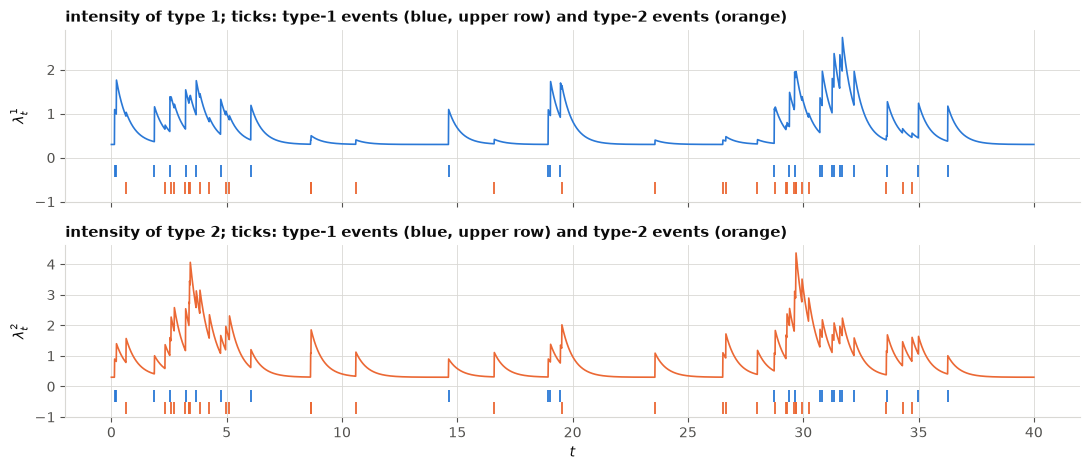

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
import math
from scipy import optimize

mu = np.array([0.3, 0.3]); A = np.array([[0.8, 0.1], [0.6, 0.8]]); beta = 2.0
Phi = A / beta
print("spectral radius of Phi:", round(max(abs(np.linalg.eigvals(Phi))), 4))
print("theoretical mean intensities (I - Phi)^{-1} mu:", np.round(np.linalg.solve(np.eye(2) - Phi, mu), 4))

def sim_mv(mu, A, beta, T, rng, burn=0.0):
    """Ogata thinning for d-variate exponential Hawkes with common decay; returns (times, types)."""
    t, ex, times, types = -burn, np.zeros(len(mu)), [], []
    while True:
        M = np.sum(mu + ex)                                    # total intensity can only fall until the next event
        w = rng.exponential(1 / M); t += w
        if t > T:
            times, types = np.array(times), np.array(types); keep = times > 0
            return times[keep], types[keep]
        ex *= math.exp(-beta * w)
        lam = mu + ex
        if rng.random() * M <= lam.sum():
            i = rng.choice(len(mu), p=lam / lam.sum())
            times.append(t); types.append(i); ex += A[:, i]

rng = np.random.default_rng(1)
t, k = sim_mv(mu, A, beta, 40.0, rng, burn=50.0)
g = np.linspace(0, 40, 4000)
fig, ax = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True)
for i, c, nm in [(0, BLUE, "type 1"), (1, ORANGE, "type 2")]:
    d = g[:, None] - t[None, :]; E = np.exp(-beta * np.where(d > 0, d, np.inf))
    lam = mu[i] + (E * A[i, k]).sum(1)
    ax[i].plot(g, lam, color=c, lw=1.2)
    ax[i].plot(t[k == 0], np.full((k == 0).sum(), -0.3), "|", color=BLUE, ms=9, mew=1.3)
    ax[i].plot(t[k == 1], np.full((k == 1).sum(), -0.7), "|", color=ORANGE, ms=9, mew=1.3)
    ax[i].set(ylabel=rf"$\lambda^{i+1}_t$", ylim=(-1, None)); ax[i].set_title(f"intensity of {nm}; ticks: type-1 events (blue, upper row) and type-2 events (orange)", loc="left")
ax[1].set_xlabel("$t$")
plt.tight_layout(); plt.show()


**Mean rates and lead–lag.** On a long path ($T = 50\,000$) the empirical rates match $(I - \Phi)^{-1}\mu$. The cross-covariance of counts in bins of width $0.25$, $\operatorname{Cov}(K^2_b, K^1_{b - \ell})$ as a function of the lag $\ell$, is strongly asymmetric: type-2 counts follow type-1 counts (positive lags) much more than they precede them.

empirical rates: [0.5728 0.7919]


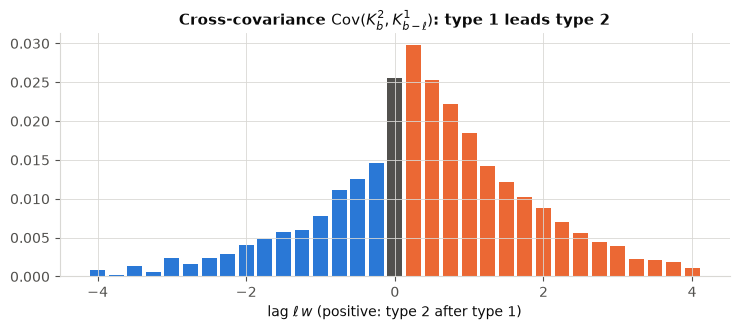

In [2]:

T = 50000.0
t, k = sim_mv(mu, A, beta, T, rng, burn=100.0)
print("empirical rates:", np.round([np.sum(k == 0) / T, np.sum(k == 1) / T], 4))
w = 0.25; nb = int(T / w)
K1 = np.bincount((t[k == 0] // w).astype(int), minlength=nb)[:nb].astype(float); K1 -= K1.mean()
K2 = np.bincount((t[k == 1] // w).astype(int), minlength=nb)[:nb].astype(float); K2 -= K2.mean()
lags = np.arange(-16, 17)
cc = [np.mean(K2[l:] * K1[:nb - l]) if l >= 0 else np.mean(K2[:nb + l] * K1[-l:]) for l in lags]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(lags * w, cc, width=0.8 * w, color=[ORANGE if l > 0 else (BLUE if l < 0 else MUTED) for l in lags])
ax.set(title=r"Cross-covariance $\mathrm{Cov}(K^2_b, K^1_{b-\ell})$: type 1 leads type 2", xlabel=r"lag $\ell\,w$ (positive: type 2 after type 1)")
plt.tight_layout(); plt.show()


**Recovering the network.** By @prp-multivariate-likelihood each row of $\Phi$ is estimated separately. We fit, for each receiving type $i$, the parameters $(\mu_i, \alpha_{i1}, \alpha_{i2}, \beta_i)$ on a path of length $T = 5000$, using the pairwise form of the intensity (pairs further apart than $15$ time units are ignored, which changes the intensities by less than $e^{-30}$ relative).

estimated mu: [0.311 0.282]   estimated beta per row: [1.988 1.729]


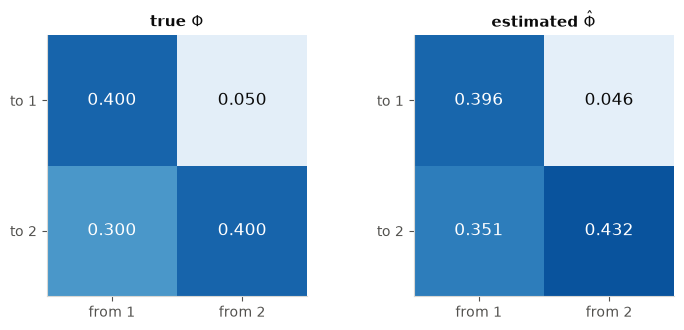

In [3]:

t, k = sim_mv(mu, A, beta, 5000.0, rng, burn=100.0); T = 5000.0
def row_nll(z, i):
    m_, a1, a2, b = np.exp(z)
    sel = k[I] == i                                             # receiving events of type i
    amp = np.where(k[J[sel]] == 0, a1, a2)
    lam = m_ + np.bincount(I[sel], amp * np.exp(-b * D[sel]), minlength=len(t))[k == i]
    comp = m_ * T + np.sum(np.where(k == 0, a1, a2) / b * (1 - np.exp(-b * (T - t))))
    return -(np.sum(np.log(lam)) - comp)
# pairs (receiver index I, source index J, delay D) within 15 time units
I, J = [], []
for a in range(len(t)):
    j0 = np.searchsorted(t, t[a] - 15.0); I.append(np.full(a - j0, a)); J.append(np.arange(j0, a))
I, J = np.concatenate(I), np.concatenate(J); D = t[I] - t[J]
est = np.zeros((2, 2)); mu_hat = np.zeros(2); beta_hat = np.zeros(2)
for i in range(2):
    r = optimize.minimize(row_nll, np.log([0.5, 0.3, 0.3, 1.0]), args=(i,), method="Nelder-Mead",
                          options={"maxiter": 4000, "xatol": 1e-7, "fatol": 1e-9})
    m_, a1, a2, b = np.exp(r.x); mu_hat[i], est[i], beta_hat[i] = m_, [a1 / b, a2 / b], b
print("estimated mu:", np.round(mu_hat, 3), "  estimated beta per row:", np.round(beta_hat, 3))
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.4))
for a, M, ttl in [(ax[0], Phi, r"true $\Phi$"), (ax[1], est, r"estimated $\hat\Phi$")]:
    a.imshow(M, cmap="Blues", vmin=0, vmax=0.5); a.grid(False)
    for (r_, c_), v in np.ndenumerate(M):
        a.text(c_, r_, f"{v:.3f}", ha="center", va="center", color=INK if v < 0.3 else "white", fontsize=12)
    a.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["from 1", "from 2"], yticklabels=["to 1", "to 2"], title=ttl)
plt.tight_layout(); plt.show()